# Librerias

In [1]:
import sys
import os
import datetime
import time
# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join('../')))


import tensorflow as tf

from src.Modelo_RNN_GRU import Simple_RNN_Model
from src.Modelo_RNN_GRU import GRU_RNN_Model
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


I0000 00:00:1794254712.865632  527926 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Instancia para modelado

In [3]:

modelo_provincia_simple = Simple_RNN_Model()
modelo_nacional_simple = Simple_RNN_Model()

modelo_gru_nacional = GRU_RNN_Model()
modelo_gru_provincia = GRU_RNN_Model()

# Carga de sets de datos

In [4]:
modelo_provincia_simple.load_data('../data/proceced/archivos_parquet/vectoria_dengue_semanal.parquet').data.drop(columns = ['region_climatica'], inplace = True)


modelo_nacional_simple.load_data('../data/proceced/archivos_parquet/vectoria_dengue_nacional_real.parquet').data.drop(
    columns = ['region_climatica', 'provincia'], inplace = True)

modelo_gru_provincia.load_data('../data/proceced/archivos_parquet/vectoria_dengue_semanal.parquet').data.drop(columns = ['region_climatica'], inplace = True)

modelo_gru_nacional.load_data('../data/proceced/archivos_parquet/vectoria_dengue_nacional_real.parquet').data.drop(
    columns = ['region_climatica', 'provincia'], inplace = True)


/tmp/ipykernel_527926/2319185718.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  modelo_provincia_simple.load_data('../data/proceced/archivos_parquet/vectoria_dengue_semanal.parquet').data.drop(columns = ['region_climatica'], inplace = True)
/tmp/ipykernel_527926/2319185718.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  modelo_nacional_simple.load_data('../data/proceced/archivos_parquet/vectoria_dengue_nacional_real.parquet').data.drop(
/tmp/ipykernel_527926/2319185718.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v

In [5]:
entradas_provincias = list(modelo_provincia_simple.data.drop(columns = 'casos_dengue').columns)

entradas_nacional = list(modelo_nacional_simple.data.drop(columns = 'casos_dengue').columns)

In [6]:

modelo_provincia_simple.set_scaled_partitions( 
                              variables_entrada=entradas_provincias, 
                              variables_salida=['casos_dengue'],
                              tamaño_ventana = 26,
                              horizonte = 4)


modelo_nacional_simple.set_scaled_partitions( 
                              variables_entrada=entradas_nacional, 
                              variables_salida=['casos_dengue'], 
                              tamaño_ventana = 26,
                              horizonte = 4)


modelo_gru_provincia.set_scaled_partitions( 
                              variables_entrada=entradas_provincias, 
                              variables_salida=['casos_dengue'], 
                              tamaño_ventana = 26,
                              horizonte = 4)


modelo_gru_nacional.set_scaled_partitions( 
                              variables_entrada=entradas_nacional, 
                              variables_salida=['casos_dengue'], 
                              tamaño_ventana = 26,
                              horizonte = 4)

In [7]:


modelo_provincia_simple.x_train



array([[[0.12598425, 0.09657061, 0.17777778, ..., 0.71102298,
         0.69490811, 0.6817538 ],
        [0.        , 0.03935006, 0.76111111, ..., 0.33474322,
         0.31959089, 0.30036051],
        [1.        , 0.03834176, 0.38888889, ..., 0.49191474,
         0.47424368, 0.45567325],
        ...,
        [0.08661417, 0.05069334, 0.76666667, ..., 0.42004009,
         0.42208907, 0.46921552],
        [0.        , 0.03960213, 0.77777778, ..., 0.26636689,
         0.20079966, 0.12293856],
        [0.12598425, 0.14219581, 0.21666667, ..., 0.61469282,
         0.66386825, 0.68026006]],

       [[0.        , 0.03935006, 0.76111111, ..., 0.33474322,
         0.31959089, 0.30036051],
        [1.        , 0.03834176, 0.38888889, ..., 0.49191474,
         0.47424368, 0.45567325],
        [0.04724409, 0.21101172, 0.59444444, ..., 0.82489616,
         0.81680853, 0.82086034],
        ...,
        [0.        , 0.03960213, 0.77777778, ..., 0.26636689,
         0.20079966, 0.12293856],
        [0.1

In [8]:

modelo_nacional_simple.x_val


array([[[ 0.        ,  0.14907471,  0.1686747 , ...,  0.92163009,
          0.85266458,  0.94984326],
        [ 0.        ,  0.04232351,  0.26506024, ...,  0.85266458,
          0.94984326,  0.94984326],
        [ 0.        ,  0.22429746,  0.21686747, ...,  0.94984326,
          0.94984326,  0.84639498],
        ...,
        [ 0.        ,  0.04095271,  0.60240964, ...,  0.46081505,
          0.78996865,  0.35109718],
        [ 0.        ,  0.03204249,  0.69879518, ...,  0.78996865,
          0.35109718,  0.39184953],
        [ 0.        ,  0.02587389,  0.74698795, ...,  0.35109718,
          0.39184953,  0.34796238]],

       [[ 0.        ,  0.04232351,  0.26506024, ...,  0.85266458,
          0.94984326,  0.94984326],
        [ 0.        ,  0.22429746,  0.21686747, ...,  0.94984326,
          0.94984326,  0.84639498],
        [ 0.        ,  0.15712817,  0.08433735, ...,  0.94984326,
          0.84639498,  0.85893417],
        ...,
        [ 0.        ,  0.03204249,  0.69879518, ...,  

In [9]:


modelo_gru_provincia.y_train


array([[0.00740741, 0.27407407, 0.17777778, 0.04074074],
       [0.27407407, 0.17777778, 0.04074074, 0.01111111],
       [0.17777778, 0.04074074, 0.01111111, 0.02962963],
       ...,
       [0.15925926, 0.05555556, 0.61851852, 0.52962963],
       [0.05555556, 0.61851852, 0.52962963, 0.02222222],
       [0.61851852, 0.52962963, 0.02222222, 0.13333333]], shape=(3471, 4))

In [10]:

modelo_gru_nacional.y_train


array([[0.32388664, 0.3340081 , 0.37955466, 0.31376518],
       [0.3340081 , 0.37955466, 0.31376518, 0.34716599],
       [0.37955466, 0.31376518, 0.34716599, 0.36234818],
       ...,
       [0.21356275, 0.20242915, 0.15283401, 0.18825911],
       [0.20242915, 0.15283401, 0.18825911, 0.1902834 ],
       [0.15283401, 0.18825911, 0.1902834 , 0.16497976]], shape=(430, 4))

# Configuracion de flujo y entrenamineto

In [13]:

modelo_provincia_simple.preparar_experimento(                                 
).model_flow_settings().model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 26, 64)         │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,252 (36.14 KB)

 Trainable params: 9,252 (36.14 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:

modelo_nacional_simple.preparar_experimento(                                 
).model_flow_settings().model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 26, 64)         │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,252 (36.14 KB)

 Trainable params: 9,252 (36.14 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:


modelo_gru_provincia.preparar_experimento(                                 
).model_flow_settings().model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 26, 64)         │        18,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,780 (108.52 KB)

 Trainable params: 27,780 (108.52 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:


modelo_gru_nacional.preparar_experimento(                                 
).model_flow_settings().model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 26, 64)         │        18,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,780 (108.52 KB)

 Trainable params: 27,780 (108.52 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:

modelo_provincia_simple.start_training(
    epochs = 600,
    callbacks = [
        
        EarlyStopping(
            monitor='val_loss', 
            mode='min',
            verbose=1, 
            patience=30,
            restore_best_weights =  True
            ),
        ModelCheckpoint(
            filepath=f"../models/RNN_Models/checkpoints/SimpleRNN_provincial.keras",
            monitor='val_loss',
            mode='min',
            save_best_only=True
        )
        
        ]
)
losses = pd.DataFrame(modelo_provincia_simple.model.history.history)

🚀 Iniciando el entrenamiento...

Epoch 1/600


E0000 00:00:1794254884.136656  527926 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - loss: 0.2388 - mae: 0.3674

E0000 00:00:1794254923.072522  527926 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


109/109 ━━━━━━━━━━━━━━━━━━━━ 44s 153ms/step - loss: 0.2388 - mae: 0.3674 - val_loss: 0.0412 - val_mae: 0.1460
Epoch 2/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 13s 121ms/step - loss: 0.0445 - mae: 0.1616 - val_loss: 0.0316 - val_mae: 0.1220
Epoch 3/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - loss: 0.0251 - mae: 0.1197 - val_loss: 0.0257 - val_mae: 0.1119
Epoch 4/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 13s 117ms/step - loss: 0.0199 - mae: 0.1042 - val_loss: 0.0271 - val_mae: 0.1085
Epoch 5/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 13s 119ms/step - loss: 0.0173 - mae: 0.0947 - val_loss: 0.0249 - val_mae: 0.1036
Epoch 6/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 12s 115ms/step - loss: 0.0157 - mae: 0.0894 - val_loss: 0.0239 - val_mae: 0.1023
Epoch 7/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 13s 119ms/step - loss: 0.0149 - mae: 0.0861 - val_loss: 0.0232 - val_mae: 0.1032
Epoch 8/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 13s 118ms/step - loss: 0.0144 - mae: 0.0844 - val_loss: 0.0233 - val_mae: 0.1030
Epoch 9/600
109/109 ━━━━━━━━━━━━━━━━

<Axes: >

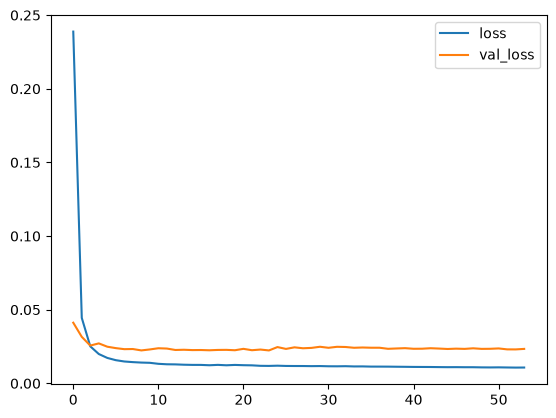

In [18]:

losses[['loss','val_loss']].plot()

<Axes: title={'center': 'MAE durante el entrenamiento (escala normalizada)'}>

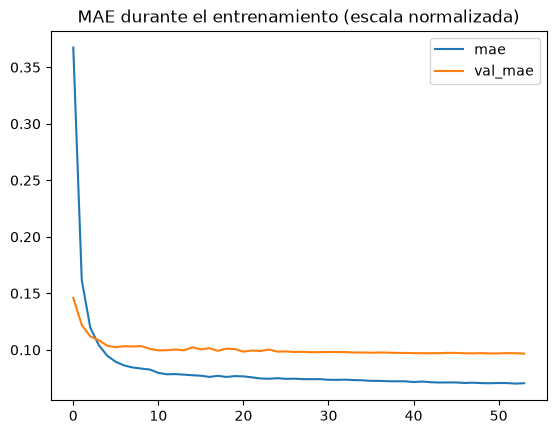

In [19]:
losses[['mae', 'val_mae']].plot(title='MAE durante el entrenamiento (escala normalizada)')


In [20]:

modelo_nacional_simple.start_training(
    epochs = 600,
    callbacks = [
        
        EarlyStopping(
            monitor='val_loss', 
            mode='min',
            verbose=1, 
            patience=30,
            restore_best_weights =  True
            ),
        ModelCheckpoint(
            filepath=f"../models/RNN_Models/checkpoints/SimpleRNN_nacional.keras",
            monitor='val_loss',
            mode='min',
            save_best_only=True
        )
        
        ]
)
losses = pd.DataFrame(modelo_nacional_simple.model.history.history)

🚀 Iniciando el entrenamiento...

Epoch 1/600


E0000 00:00:1794255581.908306  527926 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 144ms/step - loss: 0.6156 - mae: 0.6247 - val_loss: 0.4020 - val_mae: 0.4999
Epoch 2/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step - loss: 0.3284 - mae: 0.4506 - val_loss: 0.4279 - val_mae: 0.5084
Epoch 3/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.2276 - mae: 0.3748 - val_loss: 0.4310 - val_mae: 0.5102
Epoch 4/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 118ms/step - loss: 0.1865 - mae: 0.3389 - val_loss: 0.3780 - val_mae: 0.4736
Epoch 5/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step - loss: 0.1427 - mae: 0.2975 - val_loss: 0.4229 - val_mae: 0.5027
Epoch 6/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 123ms/step - loss: 0.1108 - mae: 0.2584 - val_loss: 0.3786 - val_mae: 0.4679
Epoch 7/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step - loss: 0.0889 - mae: 0.2331 - val_loss: 0.3807 - val_mae: 0.4694
Epoch 8/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 126ms/step - loss: 0.0757 - mae: 0.2143 - val_loss: 0.3970 - val_mae: 0.4822
Epoch 9/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 126ms/step - loss:

<Axes: >

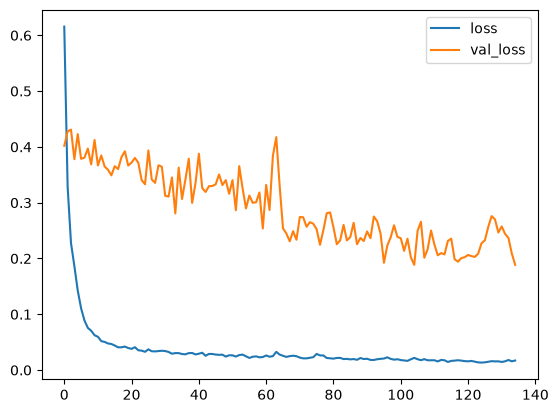

In [21]:

losses[['loss','val_loss']].plot()

<Axes: title={'center': 'MAE durante el entrenamiento (escala normalizada)'}>

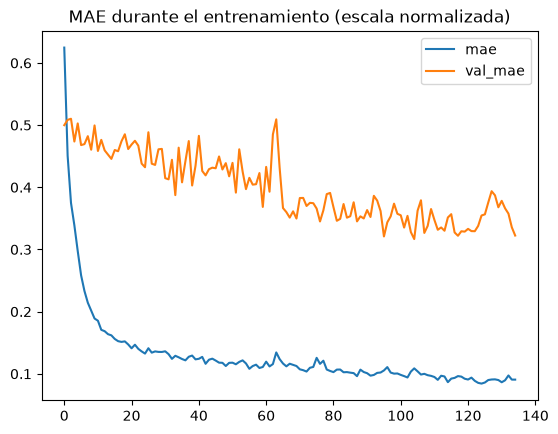

In [22]:
losses[['mae', 'val_mae']].plot(title='MAE durante el entrenamiento (escala normalizada)')


In [23]:

modelo_gru_provincia.start_training(
    epochs = 600,
    callbacks = [
        
        EarlyStopping(
            monitor='val_loss', 
            mode='min',
            verbose=1, 
            patience=30,
            restore_best_weights =  True
            ),
        ModelCheckpoint(
            filepath=f"../models/RNN_Models/checkpoints/GRU_provincial.keras",
            monitor='val_loss',
            mode='min',
            save_best_only=True
        )
        
        ]
)
losses = pd.DataFrame(modelo_gru_provincia.model.history.history)

🚀 Iniciando el entrenamiento...

Epoch 1/600


E0000 00:00:1794255817.948201  527926 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
I0000 00:00:1794255819.635752  528038 cuda_dnn.cc:461] Loaded cuDNN version 92700


109/109 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 0.0229 - mae: 0.1016 - val_loss: 0.0259 - val_mae: 0.0998
Epoch 2/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0128 - mae: 0.0762 - val_loss: 0.0243 - val_mae: 0.0981
Epoch 3/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0122 - mae: 0.0746 - val_loss: 0.0238 - val_mae: 0.0975
Epoch 4/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0120 - mae: 0.0737 - val_loss: 0.0233 - val_mae: 0.0968
Epoch 5/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0116 - mae: 0.0729 - val_loss: 0.0233 - val_mae: 0.0968
Epoch 6/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0115 - mae: 0.0724 - val_loss: 0.0232 - val_mae: 0.0965
Epoch 7/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0114 - mae: 0.0722 - val_loss: 0.0223 - val_mae: 0.0957
Epoch 8/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0114 - mae: 0.0724 - val_loss: 0.0232 - val_mae: 0.0953
Epoch 9/600
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step

<Axes: >

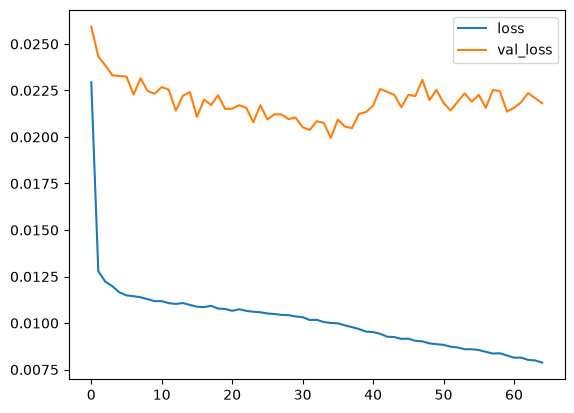

In [24]:

losses[['loss','val_loss']].plot()

<Axes: title={'center': 'MAE durante el entrenamiento (escala normalizada)'}>

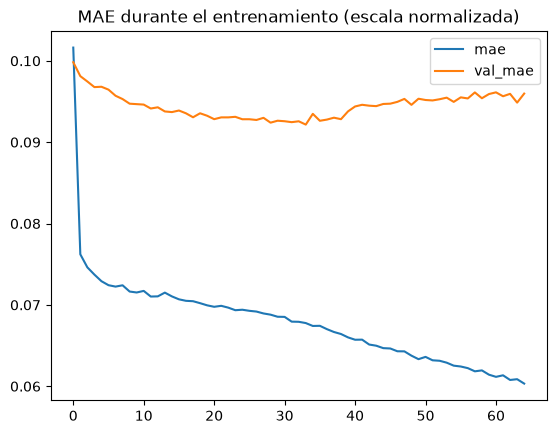

In [25]:
losses[['mae', 'val_mae']].plot(title='MAE durante el entrenamiento (escala normalizada)')


In [26]:

modelo_gru_nacional.start_training(
    epochs = 600,
    callbacks = [
        
        EarlyStopping(
            monitor='val_loss', 
            mode='min',
            verbose=1, 
            patience=30,
            restore_best_weights =  True
            ),
        ModelCheckpoint(
            filepath=f"../models/RNN_Models/checkpoints/GRU_nacional.keras",
            monitor='val_loss',
            mode='min',
            save_best_only=True
        )
        
        ]
)
losses = pd.DataFrame(modelo_gru_nacional.model.history.history)

🚀 Iniciando el entrenamiento...

Epoch 1/600


E0000 00:00:1794255964.346527  527926 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.1257 - mae: 0.2647 - val_loss: 0.3823 - val_mae: 0.4712
Epoch 2/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0481 - mae: 0.1567 - val_loss: 0.3834 - val_mae: 0.4640
Epoch 3/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0373 - mae: 0.1369 - val_loss: 0.3789 - val_mae: 0.4635
Epoch 4/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0339 - mae: 0.1278 - val_loss: 0.3814 - val_mae: 0.4677
Epoch 5/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0337 - mae: 0.1255 - val_loss: 0.3693 - val_mae: 0.4552
Epoch 6/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0325 - mae: 0.1215 - val_loss: 0.3805 - val_mae: 0.4695
Epoch 7/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0291 - mae: 0.1132 - val_loss: 0.3491 - val_mae: 0.4411
Epoch 8/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0277 - mae: 0.1122 - val_loss: 0.3164 - val_mae: 0.4131
Epoch 9/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0276 -

<Axes: >

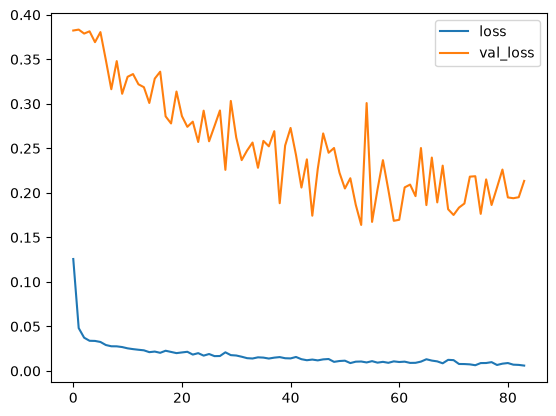

In [27]:

losses[['loss','val_loss']].plot()

<Axes: title={'center': 'MAE durante el entrenamiento (escala normalizada)'}>

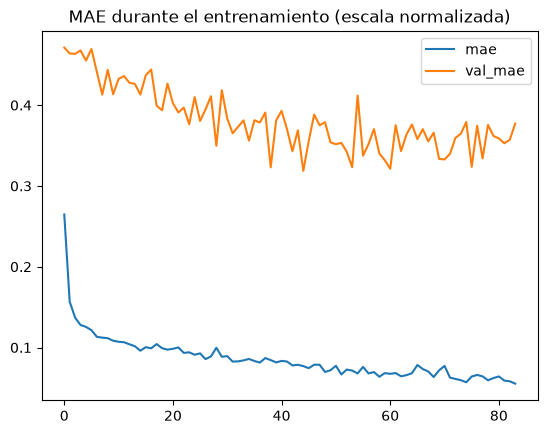

In [28]:
losses[['mae', 'val_mae']].plot(title='MAE durante el entrenamiento (escala normalizada)')


# Comparación de SimpleRNN y GRU

Ejecuta esta sección después de entrenar los cuatro modelos. Se evalúan los pesos
actuales en memoria sobre validación, con el escalador de objetivo de cada modelo,
sin reentrenar ni cargar el checkpoint compartido de ejecuciones antiguas.

**Menor MAE y RMSE significa menor error**, expresado en casos de dengue. Se compara
SimpleRNN con GRU por separado para el conjunto nacional real y el provincial
sintético; sus errores no se promedian entre conjuntos. La tabla global resume
los cuatro pasos y el detalle muestra cada paso. El RMSE global procede de todos
los errores cuadrados, no del promedio de los RMSE individuales.

**Límite provincial:** la preparación actual ordena por fecha y toma ventanas de
26 filas sin agrupar por provincia. Por ello mezcla provincias dentro de una
ventana y sus cuatro salidas no representan cuatro semanas de una misma serie.
La comparación provincial se rotula **diagnóstica** y sus horizontes como pasos:
para interpretar pronósticos semanales es necesario preparar ventanas por
provincia y volver a entrenar ambos modelos.

Los ganadores corresponden a esta ejecución y a validación, no a una prueba final
independiente ni a una superioridad estadística de una arquitectura. Las curvas
de entrenamiento anteriores están normalizadas y no sustituyen esta evaluación.


In [29]:

from IPython.display import display


def comparar_par_rnn(simple, gru, conjunto, diagnostico=False):
    """Evalúa un par con los mismos arrays y escaladores; no entrena ni guarda."""
    for nombre, modelo in [('SimpleRNN', simple), ('GRU', gru)]:
        historial = getattr(getattr(modelo.model, 'history', None), 'history', {})
        if not historial.get('loss'):
            raise ValueError(f'{conjunto} / {nombre}: ejecuta su entrenamiento antes de comparar.')
        escaladores = getattr(modelo, 'scaler_dict', {})
        if any(k not in escaladores for k in ('x_scaler', 'y_scaler')):
            raise ValueError(f'{conjunto} / {nombre}: faltan los escaladores de sus particiones.')

    for atributo in ('x_train', 'y_train', 'x_val', 'y_val'):
        a, b = np.asarray(getattr(simple, atributo)), np.asarray(getattr(gru, atributo))
        if a.size == 0 or a.shape != b.shape or not np.isfinite(a).all() or not np.isfinite(b).all():
            raise ValueError(f'{conjunto}: {atributo} vacío, no finito o de distinta forma.')
        if not np.allclose(a, b, rtol=1e-7, atol=1e-9):
            raise ValueError(f'{conjunto}: ambos modelos deben usar el mismo {atributo}, en el mismo orden.')
    if np.asarray(simple.x_val).ndim != 3 or np.asarray(simple.y_val).ndim != 2:
        raise ValueError(f'{conjunto}: se requieren ventanas 3D y objetivos 2D.')
    if simple.y_val.shape[1] != 4:
        raise ValueError(f'{conjunto}: la comparación del proyecto requiere cuatro pasos de salida.')

    for clave in ('x_scaler', 'y_scaler'):
        a, b = simple.scaler_dict[clave], gru.scaler_dict[clave]
        for atributo in ('scale_', 'min_'):
            va, vb = np.asarray(getattr(a, atributo)), np.asarray(getattr(b, atributo))
            if va.shape != vb.shape or not np.allclose(va, vb, rtol=1e-7, atol=1e-9):
                raise ValueError(f'{conjunto}: los parámetros de {clave} no coinciden.')
        ca, cb = getattr(a, 'feature_names_in_', None), getattr(b, 'feature_names_in_', None)
        if (ca is None) != (cb is None) or (ca is not None and not np.array_equal(ca, cb)):
            raise ValueError(f'{conjunto}: el orden de columnas de {clave} no coincide.')

    resultados, filas = {}, []
    for nombre, modelo in [('SimpleRNN', simple), ('GRU', gru)]:
        resultado = modelo.evaluar(
            y_scaler=modelo.scaler_dict['y_scaler'],
            x=modelo.x_val, y=modelo.y_val, graficar=False,
        ).resultado
        resultados[nombre] = resultado
        tabla = resultado['metricas'].copy()
        if not np.isfinite(tabla[['MAE', 'RMSE']].to_numpy()).all():
            raise ValueError(f'{conjunto} / {nombre}: hay métricas no finitas.')
        tabla['modelo'] = nombre
        tabla.insert(0, 'conjunto', conjunto)
        tabla['ventanas'] = len(resultado['reales'])
        if diagnostico:
            tabla['horizonte'] = tabla['horizonte'].str.replace('semana_', 'paso_', regex=False)
        filas.append(tabla)
    reales_a, reales_b = resultados['SimpleRNN']['reales'], resultados['GRU']['reales']
    if (not reales_a.columns.equals(reales_b.columns)
            or reales_a.shape != reales_b.shape
            or not np.allclose(reales_a, reales_b, rtol=1e-7, atol=1e-9)):
        raise ValueError(f'{conjunto}: los valores reales desescalados no coinciden.')
    return pd.concat(filas, ignore_index=True), resultados


def resumir_ganadores(tabla):
    """Ganador por conjunto, horizonte y métrica; admite empates y referencia cero."""
    filas = []
    for (conjunto, horizonte), grupo in tabla.groupby(['conjunto', 'horizonte'], sort=False):
        valores = grupo.set_index('modelo')
        for metrica in ('MAE', 'RMSE'):
            simple = float(valores.loc['SimpleRNN', metrica])
            gru = float(valores.loc['GRU', metrica])
            empate = np.isclose(simple, gru, rtol=1e-6, atol=1e-8)
            ganador = 'Empate' if empate else ('GRU' if gru < simple else 'SimpleRNN')
            mejora = 100 * (simple - gru) / simple if simple != 0 else (0.0 if gru == 0 else np.nan)
            filas.append({'conjunto': conjunto, 'horizonte': horizonte, 'metrica': metrica,
                          'SimpleRNN': simple, 'GRU': gru, 'mejor_modelo': ganador,
                          'mejora_GRU_pct': mejora})
    return pd.DataFrame(filas)


In [30]:
# Las salidas se calculan ahora: no se reutilizan las salidas antiguas guardadas.
pares_comparacion = [
    ('Nacional (real)', modelo_nacional_simple, modelo_gru_nacional, False),
    ('Provincial (diagnóstico)', modelo_provincia_simple, modelo_gru_provincia, True),
]
tablas_comparacion = []
resultados_comparacion = {}
for conjunto, simple, gru, diagnostico in pares_comparacion:
    tabla, resultados = comparar_par_rnn(simple, gru, conjunto, diagnostico)
    tablas_comparacion.append(tabla)
    resultados_comparacion[conjunto] = resultados

comparacion_modelos = pd.concat(tablas_comparacion, ignore_index=True)
comparacion_global = comparacion_modelos.query("horizonte == 'global'").copy()
comparacion_horizontes = comparacion_modelos.query("horizonte != 'global'").copy()
ganadores_comparacion = resumir_ganadores(comparacion_modelos)

for conjunto, grupo in comparacion_global.groupby('conjunto', sort=False):
    print(f'{conjunto} — errores globales en casos de dengue; menor es mejor')
    display(grupo[['modelo', 'ventanas', 'MAE', 'RMSE']].set_index('modelo')
            .style.format({'MAE': '{:.3f}', 'RMSE': '{:.3f}'})
            .highlight_min(subset=['MAE', 'RMSE'], color='#d9ead3'))

print('Detalle de los cuatro horizontes (provincial: pasos de filas, no semanas):')
display(comparacion_horizontes.set_index(['conjunto', 'horizonte', 'modelo'])
        [['MAE', 'RMSE']].sort_index().style.format('{:.3f}'))


E0000 00:00:1794255995.335909  527926 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Nacional (real) — errores globales en casos de dengue; menor es mejor


,ventanas,MAE,RMSE
modelo,,,
SimpleRNN,86,312.921,429.054
GRU,86,319.259,400.101


Provincial (diagnóstico) — errores globales en casos de dengue; menor es mejor


,ventanas,MAE,RMSE
modelo,,,
SimpleRNN,853,27.080,40.372
GRU,853,25.241,38.138


Detalle de los cuatro horizontes (provincial: pasos de filas, no semanas):


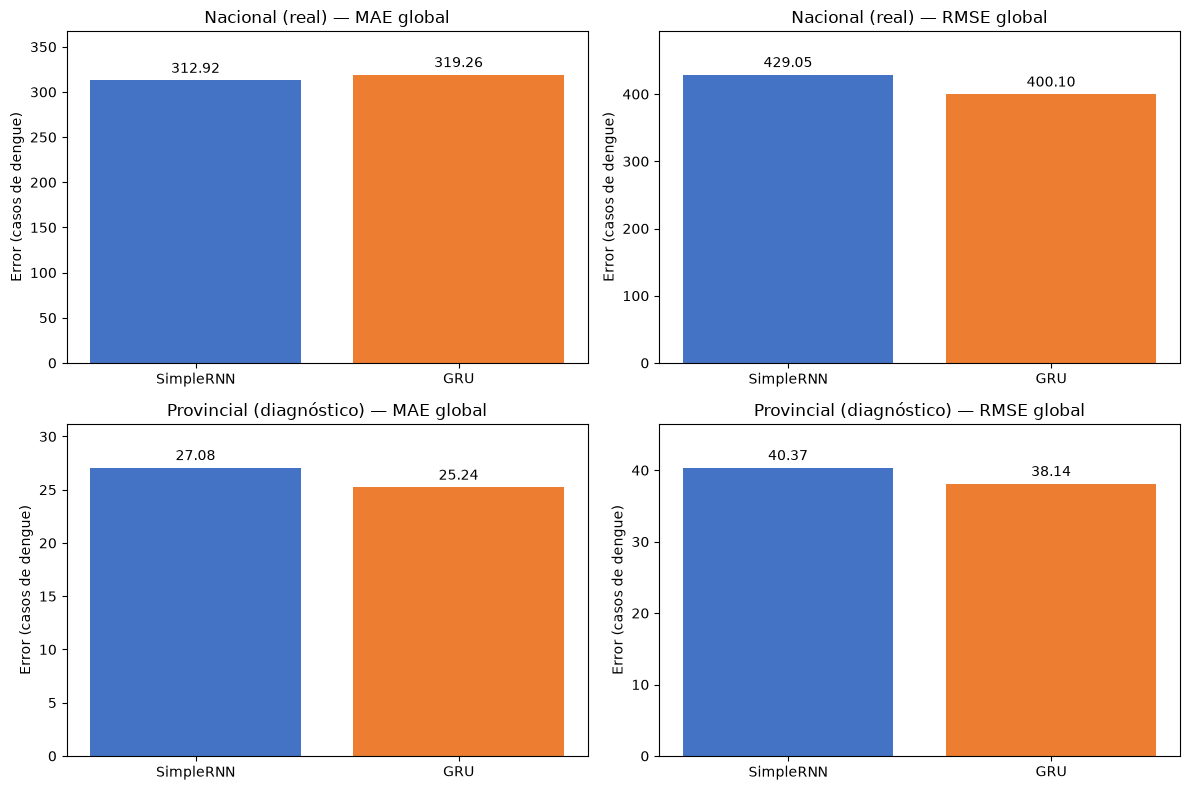

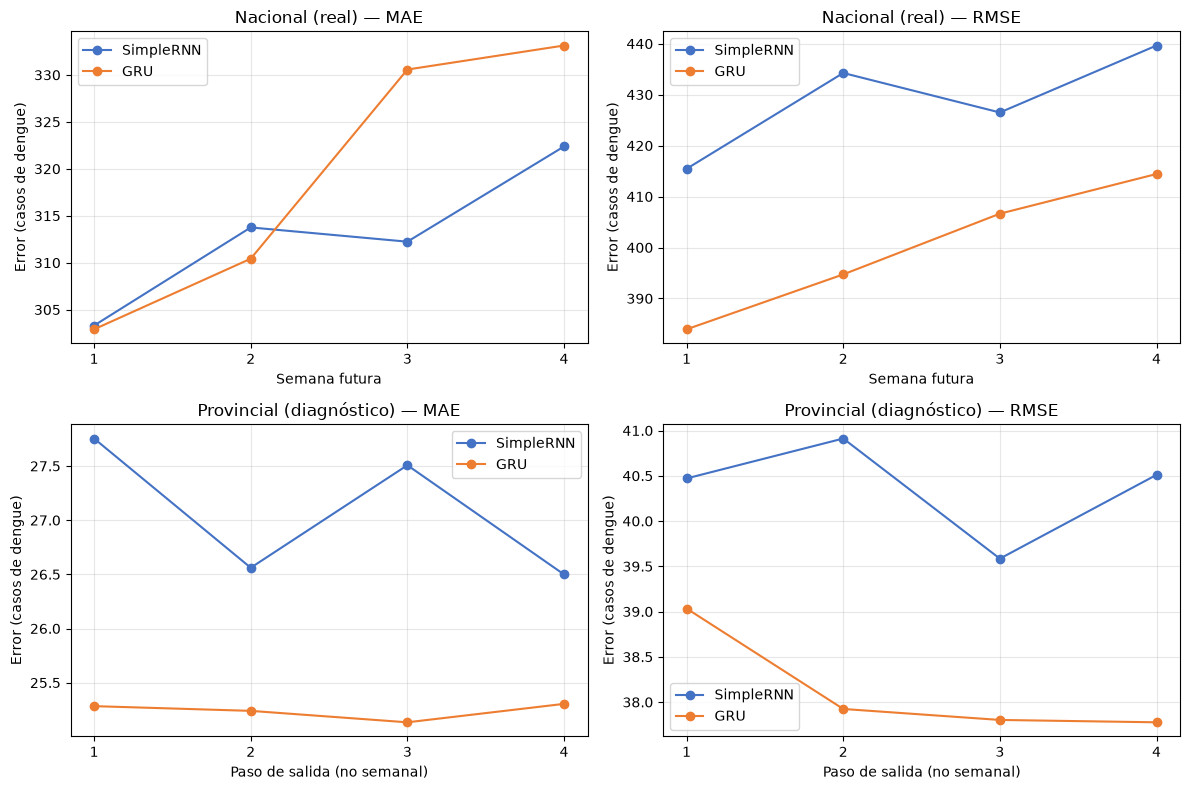

In [31]:
# Comparación global y evolución del error por horizonte.
figura_global, ejes_global = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)
figura_horizontes, ejes_horizontes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)
for fila, (conjunto, _, _, diagnostico) in enumerate(pares_comparacion):
    globales = comparacion_global.query('conjunto == @conjunto').set_index('modelo')
    detalle = comparacion_horizontes.query('conjunto == @conjunto')
    horizontes = [f"{'paso' if diagnostico else 'semana'}_{i}" for i in range(1, 5)]
    for columna, metrica in enumerate(['MAE', 'RMSE']):
        ax = ejes_global[fila, columna]
        valores = globales.loc[['SimpleRNN', 'GRU'], metrica]
        barras = ax.bar(valores.index, valores.values, color=['#4472c4', '#ed7d31'])
        ax.bar_label(barras, fmt='%.2f', padding=3)
        ax.margins(y=0.15)
        ax.set(title=f'{conjunto} — {metrica} global', ylabel='Error (casos de dengue)')
        ax = ejes_horizontes[fila, columna]
        for nombre, color in [('SimpleRNN', '#4472c4'), ('GRU', '#ed7d31')]:
            valores = detalle.query('modelo == @nombre').set_index('horizonte').loc[horizontes, metrica]
            ax.plot(range(1, 5), valores, marker='o', color=color, label=nombre)
        ax.set(title=f'{conjunto} — {metrica}', ylabel='Error (casos de dengue)',
               xlabel='Paso de salida (no semanal)' if diagnostico else 'Semana futura',
               xticks=[1, 2, 3, 4])
        ax.grid(alpha=0.3)
        ax.legend()
figura_global.tight_layout()
figura_horizontes.tight_layout()
plt.show()


In [32]:
print('Ganadores por métrica y horizonte (empate con tolerancia numérica):')
display(ganadores_comparacion.style.format(
    {'SimpleRNN': '{:.3f}', 'GRU': '{:.3f}', 'mejora_GRU_pct': '{:+.2f}%'}, na_rep='No definida'))
print('Mejora GRU positiva: menor error que SimpleRNN; negativa: mayor error. '
      'Si SimpleRNN tiene error cero y GRU no, el porcentaje no está definido.')

for conjunto, grupo in ganadores_comparacion.query("horizonte == 'global'").groupby('conjunto', sort=False):
    mejores = grupo.set_index('metrica')['mejor_modelo']
    print(f"{conjunto}: mejor MAE = {mejores['MAE']}; mejor RMSE = {mejores['RMSE']}.")
    if mejores['MAE'] != mejores['RMSE']:
        print('Las métricas no señalan un único ganador; revisa el detalle por horizonte.')
print('El resultado provincial es diagnóstico por la mezcla actual de provincias en las ventanas. '
      'La comparación nacional corresponde a validación, no a prueba final.')


Ganadores por métrica y horizonte (empate con tolerancia numérica):


,conjunto,horizonte,metrica,SimpleRNN,GRU,mejor_modelo,mejora_GRU_pct
0,Nacional (real),global,MAE,312.921,319.259,SimpleRNN,-2.03%
1,Nacional (real),global,RMSE,429.054,400.101,GRU,+6.75%
2,Nacional (real),semana_1,MAE,303.313,302.909,GRU,+0.13%
3,Nacional (real),semana_1,RMSE,415.448,383.947,GRU,+7.58%
4,Nacional (real),semana_2,MAE,313.756,310.428,GRU,+1.06%
5,Nacional (real),semana_2,RMSE,434.248,394.722,GRU,+9.10%
6,Nacional (real),semana_3,MAE,312.240,330.571,SimpleRNN,-5.87%
7,Nacional (real),semana_3,RMSE,426.497,406.638,GRU,+4.66%
8,Nacional (real),semana_4,MAE,322.377,333.128,SimpleRNN,-3.34%
9,Nacional (real),semana_4,RMSE,439.637,414.424,GRU,+5.73%


Mejora GRU positiva: menor error que SimpleRNN; negativa: mayor error. Si SimpleRNN tiene error cero y GRU no, el porcentaje no está definido.
Nacional (real): mejor MAE = SimpleRNN; mejor RMSE = GRU.
Las métricas no señalan un único ganador; revisa el detalle por horizonte.
Provincial (diagnóstico): mejor MAE = GRU; mejor RMSE = GRU.
El resultado provincial es diagnóstico por la mezcla actual de provincias en las ventanas. La comparación nacional corresponde a validación, no a prueba final.


In [33]:
# Una vez terminado model.fit(...)
#nombre_archivo = "../models/RNN_Models/RNN_Vector_1.keras"

# Guardar el modelo completo
# .model.save(nombre_archivo)
#print(f"Modelo guardado exitosamente en: {nombre_archivo}")
